# Назначение самолёта по фотографии: сравнение двух локальных VLM

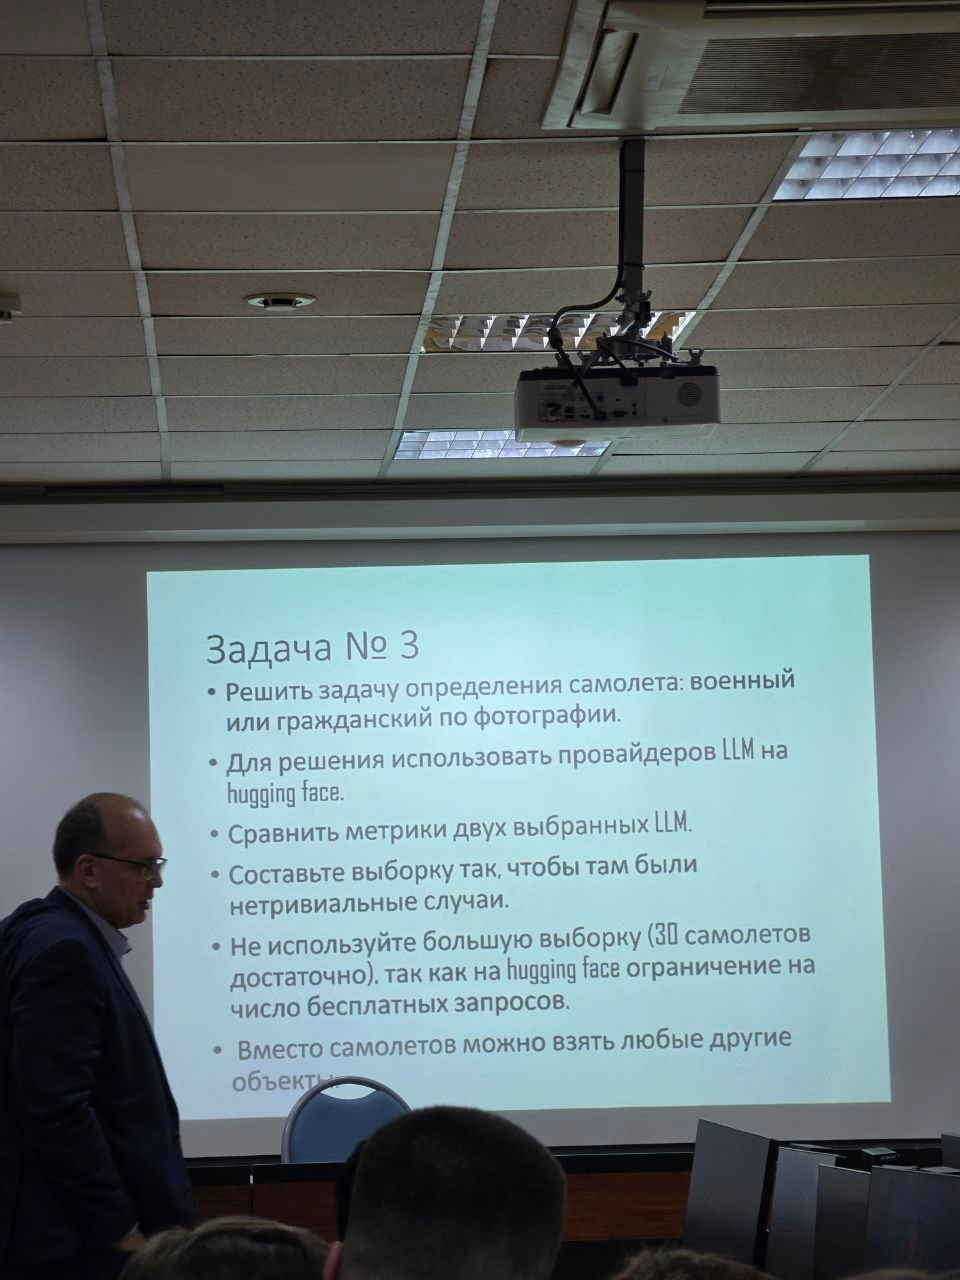

Задача № 3- Решить задачу определения самолета: военный или гражданский по фотографии.
- Для решения использовать провайдеров LLM на hugging face.
- Сравнить метрики двух выбранных LLM.
- Составьте выборку так, чтобы там были нетривиальные случаи.
- Не используйте большую выборку (30 самолетов достаточно), так как на hugging face ограничение на число бесплатных запросов.
- Вместо самолетов можно взять любые другие объекты.

Исследуется классификация назначения самолётов: 30 исходных изображений из проверочной части FGVC-Aircraft 2013b и 10 преобразованных копий, по 5 каждого класса. Сопоставляются Qwen2.5-VL-3B-Instruct (`qwen2.5vl:3b`) и Gemma 3 4B IT (`gemma3:4b`). Каждый полный запуск выполняет 80 новых запросов, не считая двух проверочных. Бинарные метки назначены по типу самолёта. Гражданская часть содержит пассажирские и региональные типы; преобразования проверяют устойчивость распознавания, но не расширяют набор типов самолётов.

Источник: FGVC-Aircraft <https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/>; Maji et al., *Fine-Grained Visual Classification of Aircraft* (2013). Исследование проводится локально; моделям передаются полные исходные JPEG и преобразованные PNG. Рабочий каталог ядра должен быть `practice_3`.

## Подготовка выборки

Манифест задаёт неизменный состав выборки. Если все выбранные JPEG уже доступны, проверяются состав, метки и SHA-256 файлов без обращения к сети и архиву. Это проверка локальной целостности, а не повторная сверка с исходными аннотациями. Если данных недостаточно, используется архив FGVC-Aircraft с официальной страницы; HTTPS проверяется по корневым сертификатам `certifi`. Допустимы две известные MD5: `d4acdd33327262359767eeaa97a4f732` ранее использованного архива и `32eca553f897e747706144f3bb444df0`, опубликованная Oxford. При работе с архивом дополнительно сверяются аннотации и SHA-256 снимков; существующие JPEG не перезаписываются.

In [11]:
from pathlib import Path
import csv, hashlib, tarfile, urllib.request, json, time, base64, os, ssl, shutil
import certifi
from collections import Counter
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageFilter
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / 'data'
IMAGES = DATA / 'images'
DATA.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)
ARCHIVE = DATA / 'fgvc-aircraft-2013b.tar.gz'
ARCHIVE_URL = 'https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/archives/fgvc-aircraft-2013b.tar.gz'
ARCHIVE_MD5 = 'd4acdd33327262359767eeaa97a4f732'
OXFORD_MD5 = '32eca553f897e747706144f3bb444df0'

# Локальные снимки проверяются по манифесту; архив требуется только для восстановления недостающих данных
def prepare_dataset():
    manifest_path = DATA / 'manifest.csv'
    sample = {'0704268': 'civilian', '1881962': 'civilian', '1818227': 'civilian', '1237861': 'civilian', '0127496': 'civilian', '1700645': 'civilian', '1396941': 'civilian', '0065291': 'civilian', '0422938': 'civilian', '1788036': 'civilian', '1601262': 'civilian', '1586117': 'civilian', '1647701': 'civilian', '1222169': 'civilian', '0066278': 'civilian', '1317747': 'military', '2186726': 'military', '1997801': 'military', '1375880': 'military', '1362024': 'military', '0747565': 'military', '0141433': 'military', '1120498': 'military', '1764706': 'military', '2118873': 'military', '1966899': 'military', '1898052': 'military', '1244763': 'military', '1570911': 'military', '2163696': 'military'}
    if manifest_path.exists():
        with manifest_path.open(encoding='utf-8') as handle:
            rows = list(csv.DictReader(handle))
        assert len(rows) == len(sample) and {row['image_id'] for row in rows} == set(sample), 'Нарушен состав выборки'
        complete = True
        for row in rows:
            assert row['label'] == sample[row['image_id']] and row['split'] == 'test', f"Некорректная метка или часть выборки: {row['image_id']}"
            assert row['source_md5'] in (ARCHIVE_MD5, OXFORD_MD5), 'Неизвестная контрольная сумма исходного архива'
            image_path = IMAGES / f"{row['image_id']}.jpg"
            if image_path.exists():
                assert hashlib.sha256(image_path.read_bytes()).hexdigest() == row['image_sha256'], f"Не совпадает SHA-256 снимка: {row['image_id']}"
            else:
                complete = False
        if complete:
            print(f'Проверены {len(rows)} локальных снимков; загрузка архива не требуется.')
            return rows
    if not ARCHIVE.exists():
        temporary = ARCHIVE.with_suffix('.download')
        try:
            context = ssl.create_default_context(cafile=certifi.where())
            with urllib.request.urlopen(ARCHIVE_URL, context=context, timeout=60) as response, temporary.open('wb') as handle:
                shutil.copyfileobj(response, handle, length=1024 * 1024)
            temporary.replace(ARCHIVE)
        finally:
            temporary.unlink(missing_ok=True)
    # Архив читается частями, чтобы не размещать несколько гигабайт в оперативной памяти
    checksum = hashlib.md5()
    with ARCHIVE.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            checksum.update(chunk)
    digest = checksum.hexdigest()
    assert digest in (ARCHIVE_MD5, OXFORD_MD5), f'Не совпадает MD5 архива: {digest}'
    print(f'Архив проверен: MD5 {digest}')
    if not manifest_path.exists():
        with tarfile.open(ARCHIVE, 'r:gz') as source:
            members = {Path(member.name).name: member for member in source.getmembers() if member.isfile()}
            variants = source.extractfile(members['images_variant_test.txt']).read().decode().splitlines()
            boxes = source.extractfile(members['images_box.txt']).read().decode().splitlines()
            variants_by_id = {line.split(' ', 1)[0]: line.split(' ', 1)[1] for line in variants}
            boxes_by_id = {line.split()[0]: line.split()[1:] for line in boxes}
            rows = []
            for image_id, label in sample.items():
                box = list(map(int, boxes_by_id[image_id]))
                image_member = members[f'{image_id}.jpg']
                image_bytes = source.extractfile(image_member).read()
                rows.append({'image_id': image_id, 'variant': variants_by_id[image_id], 'split': 'test', 'label': label, 'selection_reason': 'Approved fixed sample', 'difficulty': 'not independently assessed', 'source': 'Oxford FGVC-Aircraft 2013b', 'source_md5': digest, 'image_sha256': hashlib.sha256(image_bytes).hexdigest(), 'bbox_xyxy': ','.join(map(str, box))})
        generated_manifest = DATA / 'manifest.csv.tmp'
        with generated_manifest.open('w', newline='', encoding='utf-8') as handle:
            writer = csv.DictWriter(handle, fieldnames=rows[0].keys())
            writer.writeheader()
            writer.writerows(rows)
        generated_manifest.replace(manifest_path)
    rows = list(csv.DictReader(manifest_path.open(encoding='utf-8')))
    assert len(rows) == 30 and {row['image_id'] for row in rows} == set(sample)
    assert Counter(row['label'] for row in rows) == {'civilian': 15, 'military': 15}
    with tarfile.open(ARCHIVE, 'r:gz') as archive:
        names = {Path(member.name).name: member for member in archive.getmembers() if member.isfile()}
        variants = {line.split(' ', 1)[0]: line.split(' ', 1)[1] for line in archive.extractfile(names['images_variant_test.txt']).read().decode().splitlines()}
        boxes = {line.split()[0]: ','.join(line.split()[1:]) for line in archive.extractfile(names['images_box.txt']).read().decode().splitlines()}
        for row in rows:
            assert row['label'] == sample[row['image_id']] and row['variant'] == variants[row['image_id']] and row['split'] == 'test'
            assert row['source_md5'] in (ARCHIVE_MD5, OXFORD_MD5) and row['bbox_xyxy'] == boxes[row['image_id']], f'Manifest does not match pinned archive annotations: {row["image_id"]}'
            image_path = IMAGES / f"{row['image_id']}.jpg"
            member = names.get(f"{row['image_id']}.jpg")
            if member is None:
                raise FileNotFoundError(f"Image not found in official archive: {row['image_id']}")
            original_bytes = archive.extractfile(member).read()
            assert hashlib.sha256(original_bytes).hexdigest() == row['image_sha256'], f"Manifest image hash differs from archive: {row['image_id']}"
            if not image_path.exists():
                image_path.write_bytes(original_bytes)
            actual = hashlib.sha256(image_path.read_bytes()).hexdigest()
            assert actual == row['image_sha256'], f"JPEG SHA-256 mismatch: {row['image_id']}"
    print(f'Validated {len(rows)} original test images; labels: {dict(Counter(row["label"] for row in rows))}')
    return rows

manifest = prepare_dataset()

Проверены 30 локальных снимков; загрузка архива не требуется.


## Контактный лист

Рамки FGVC применяются только к отображению. Запросы к моделям используют полный исходный JPEG, который сверяется с хешем из манифеста.

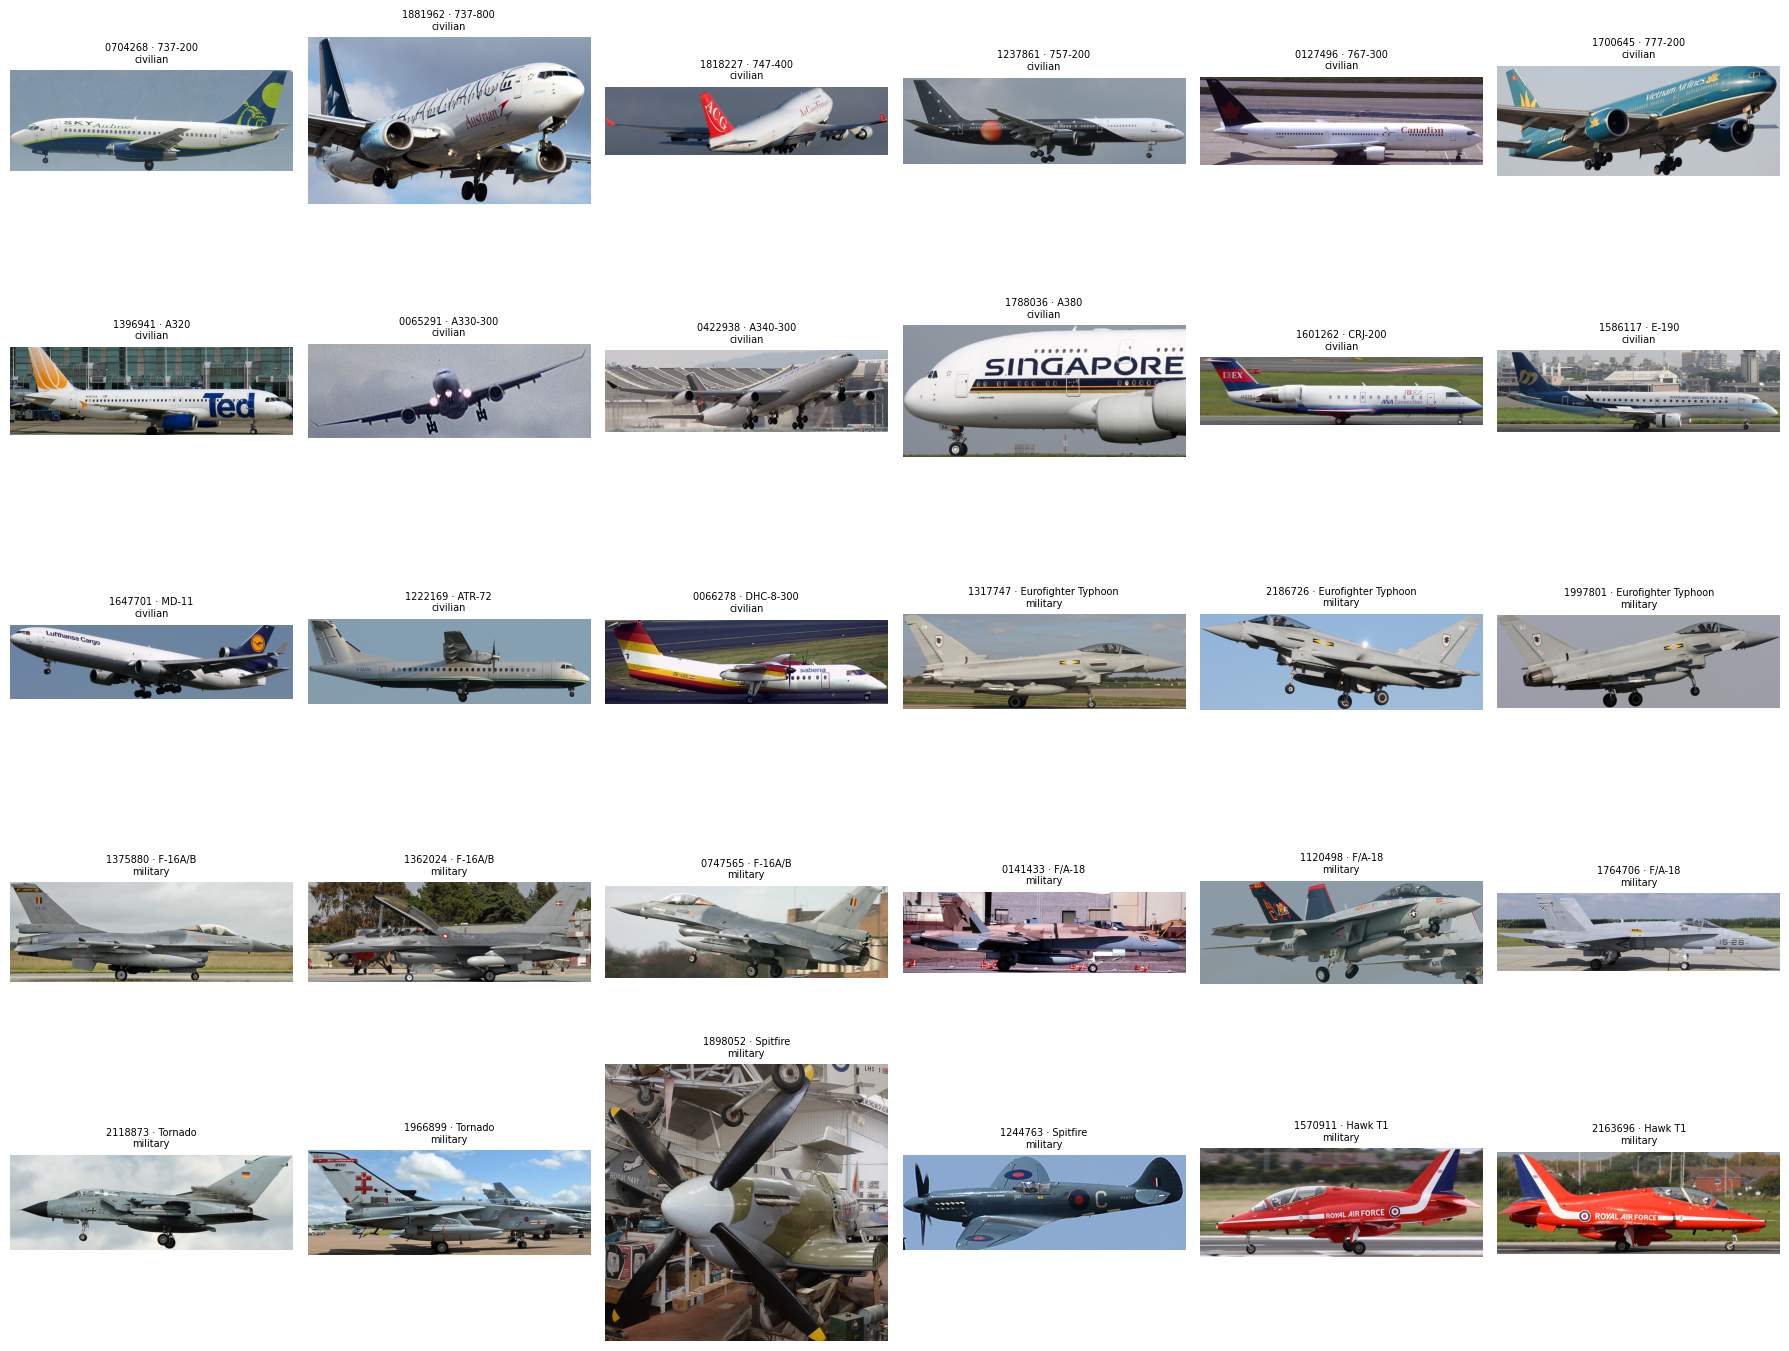

In [12]:
fig, axes = plt.subplots(5, 6, figsize=(18, 14))
for ax, row in zip(axes.flat, manifest):
    with Image.open(IMAGES / f"{row['image_id']}.jpg") as image:
        x0, y0, x1, y1 = map(int, row['bbox_xyxy'].split(','))
        ax.imshow(image.crop((x0, y0, x1, y1)))
    ax.set_title(f"{row['image_id']} · {row['variant']}\n{row['label']}", fontsize=7)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Усложнение выборки

Заранее выбраны пять разных исходников каждого класса, без отбора по ответам моделей. Для обоих классов применяются одинаковые преобразования: яркость 20% исходной, поворот на 35°, гауссово размытие с радиусом 5 пикселей, уменьшение длинной стороны до 96 пикселей с восстановлением размера, затемнение до 25% вместе с поворотом на −30°. Поворот расширяет границы кадра и не обрезает самолёт.

Копии сохраняются отдельно в PNG без потерь; исходные JPEG не меняются. Параметры и контрольные суммы записываются в `data/manifest-extended.csv`. На обзорном листе показаны полные кадры, передаваемые моделям. Преобразованные изображения не являются независимыми наблюдениями; одного примера на класс недостаточно для вывода об отдельном виде искажения.

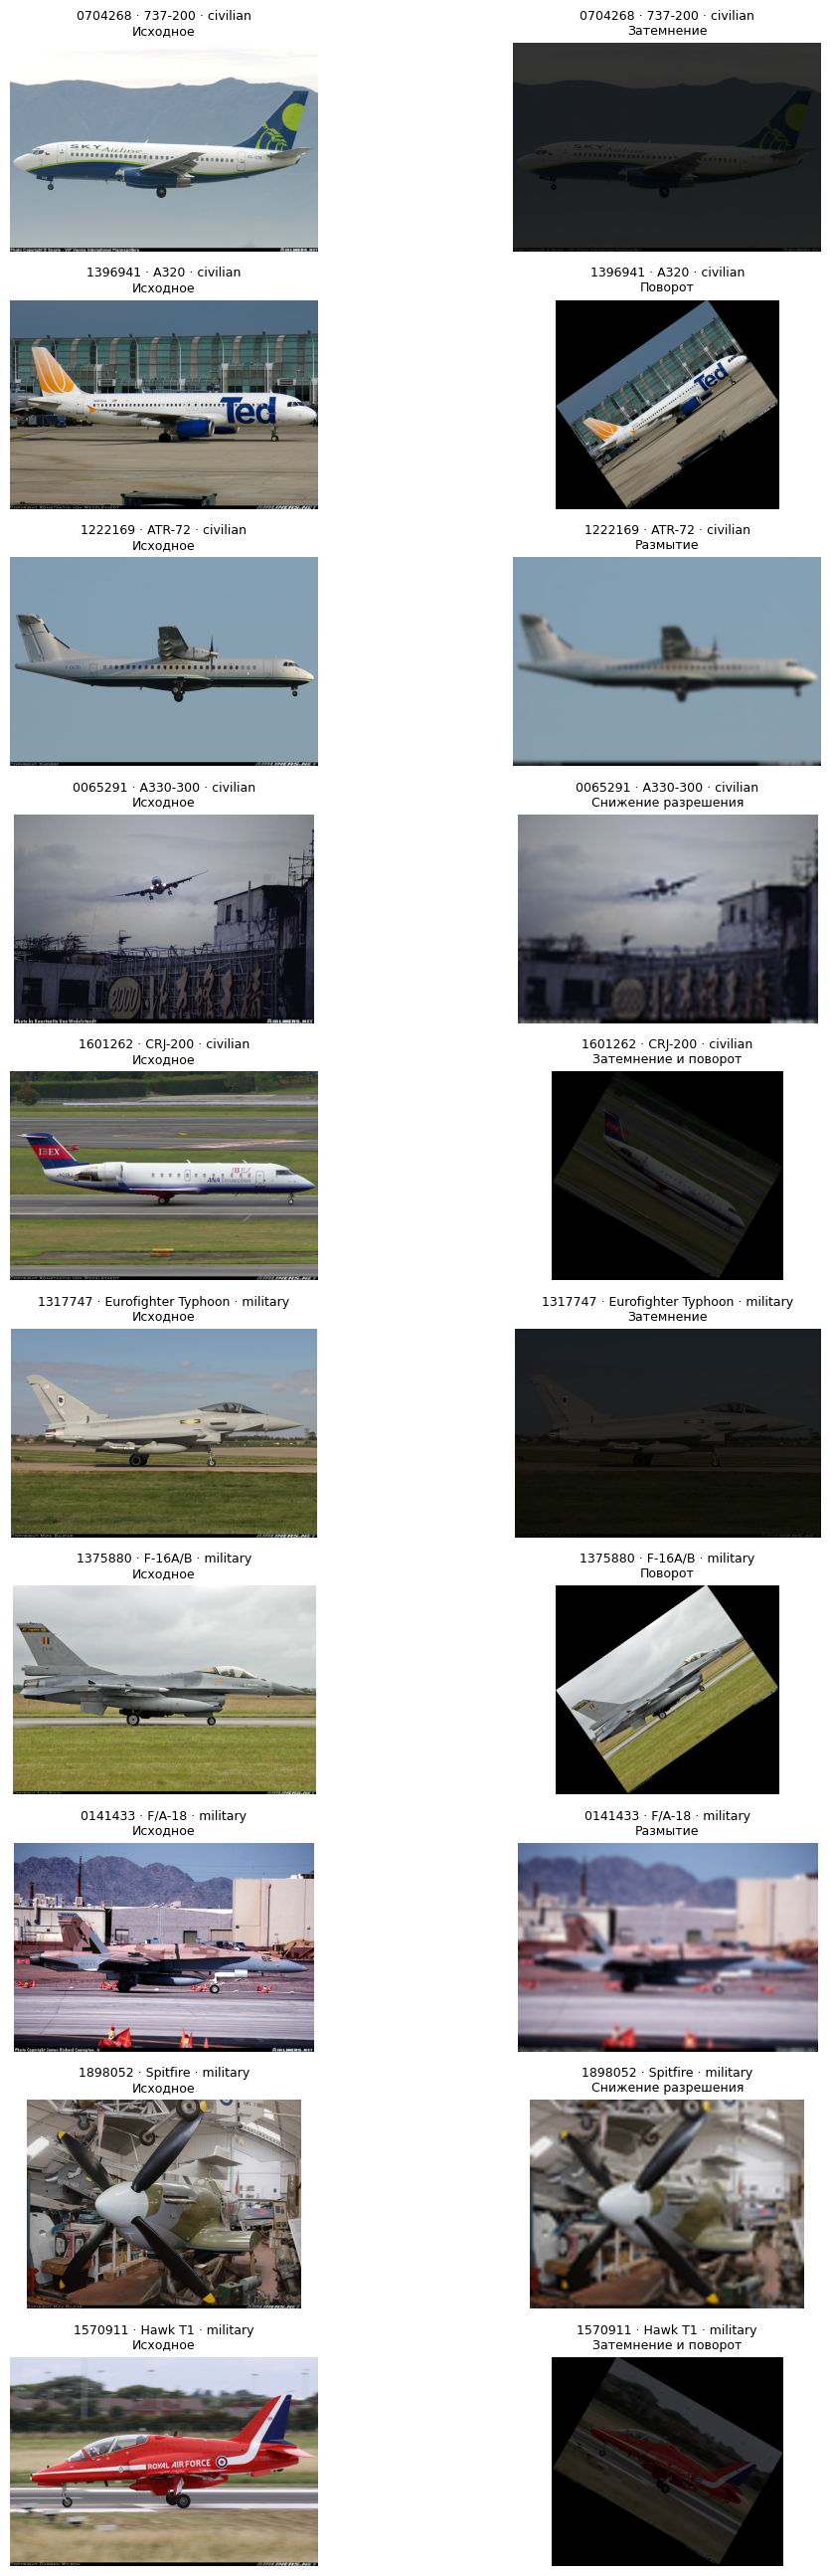

In [13]:
TRANSFORMS = ['Затемнение', 'Поворот', 'Размытие', 'Снижение разрешения', 'Затемнение и поворот']
TRANSFORM_PARAMETERS = ['яркость=0.20', 'угол=35°', 'радиус=5 пикселей', 'длинная сторона=96 пикселей', 'яркость=0.25; угол=-30°']
SELECTED = {'civilian': ['0704268', '1396941', '1222169', '0065291', '1601262'],
            'military': ['1317747', '1375880', '0141433', '1898052', '1570911']}

# Преобразования воспроизводимы; исходные файлы сохраняются, а копии получают собственные идентификаторы и контрольные суммы
def prepare_extended_dataset(originals):
    derived = DATA / 'transformed'
    derived.mkdir(exist_ok=True)
    samples = []
    for row in originals:
        path = IMAGES / f"{row['image_id']}.jpg"
        assert hashlib.sha256(path.read_bytes()).hexdigest() == row['image_sha256']
        samples.append({'image_id': row['image_id'], 'source_image_id': row['image_id'], 'variant': row['variant'], 'label': row['label'], 'condition': 'Исходное', 'parameters': '', 'image_path': str(path.relative_to(DATA)), 'image_sha256': row['image_sha256']})
    by_id = {row['image_id']: row for row in originals}
    for label, image_ids in SELECTED.items():
        for index, image_id in enumerate(image_ids):
            row = by_id[image_id]
            assert row['label'] == label
            with Image.open(IMAGES / f'{image_id}.jpg') as source:
                image = source.convert('RGB')
            if index == 0:
                image = ImageEnhance.Brightness(image).enhance(0.20)
            elif index == 1:
                image = image.rotate(35, resample=Image.Resampling.BICUBIC, expand=True)
            elif index == 2:
                image = image.filter(ImageFilter.GaussianBlur(radius=5))
            elif index == 3:
                size = image.size
                image.thumbnail((96, 96), Image.Resampling.LANCZOS)
                image = image.resize(size, Image.Resampling.BICUBIC)
            else:
                image = ImageEnhance.Brightness(image).enhance(0.25)
                image = image.rotate(-30, resample=Image.Resampling.BICUBIC, expand=True)
            sample_id = f'{image_id}_transformed_{index + 1}'
            path = derived / f'{sample_id}.png'
            image.save(path, format='PNG')
            samples.append({'image_id': sample_id, 'source_image_id': image_id, 'variant': row['variant'], 'label': label, 'condition': TRANSFORMS[index], 'parameters': TRANSFORM_PARAMETERS[index], 'image_path': str(path.relative_to(DATA)), 'image_sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
    assert len(samples) == 40 and len({row['image_id'] for row in samples}) == len(samples)
    assert Counter(row['label'] for row in samples) == {'civilian': 20, 'military': 20}
    with (DATA / 'manifest-extended.csv').open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=samples[0].keys())
        writer.writeheader()
        writer.writerows(samples)
    return samples

samples = prepare_extended_dataset(manifest)
transformed = [row for row in samples if row['condition'] != 'Исходное']
fig, axes = plt.subplots(len(transformed), 2, figsize=(12, 26))
# В каждой строке показана пара полных кадров, а не обрезка по ограничивающей рамке
for axes_pair, row in zip(axes, transformed):
    paths = [IMAGES / f"{row['source_image_id']}.jpg", DATA / row['image_path']]
    for ax, path, title in zip(axes_pair, paths, ['Исходное', row['condition']]):
        with Image.open(path) as image:
            ax.imshow(image)
        ax.set_title(f"{row['source_image_id']} · {row['variant']} · {row['label']}\n{title}", fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()


## Подключение Ollama и проверочный запрос

Проверяется версия сервера, а отсутствующие точные теги загружаются через `/api/pull`. Digest сохраняется в записях результатов. Проверочный запрос подтверждает, что каждая модель принимает изображение и возвращает одну из заданных меток. Таймаут 600 секунд относится к одному HTTP-запросу.

In [23]:
OLLAMA_URL = 'http://practice3-ollama:11434'
MODELS = ('qwen2.5vl:3b', 'gemma3:4b')
PROMPT = 'Определите основное назначение самолёта. Верните JSON-объект строго вида {"label": "civilian"} или {"label": "military"}.'
OPTIONS = {'temperature': 0, 'num_ctx': 4096, 'num_predict': 32}
REQUEST_TIMEOUT = 600

# Метка принимается из JSON-поля label или как точная строка; иной формат остаётся невалидным
def parse_label(raw):
    try:
        value = json.loads(raw)
    except (json.JSONDecodeError, TypeError):
        value = None
    if isinstance(value, dict) and value.get('label') in ('civilian', 'military'):
        return value['label']
    return raw.strip() if isinstance(raw, str) and raw.strip() in ('civilian', 'military') else ''

# Задержка охватывает HTTP-запрос целиком, а сетевые сбои и неверный JSON возвращаются как диагностика
def call_model(model, payload):
    body = {'model': model, 'messages': [{'role': 'user', 'content': PROMPT, 'images': [base64.b64encode(payload).decode('ascii')]}], 'stream': False, 'format': 'json', 'options': OPTIONS}
    started = time.perf_counter()
    try:
        response = requests.post(f'{OLLAMA_URL}/api/chat', json=body, timeout=REQUEST_TIMEOUT)
        response.raise_for_status()
        try:
            answer = response.json()
            # Корректный синтаксис JSON не гарантирует наличия текстового ответа модели
            if not isinstance(answer, dict) or not isinstance(answer.get('message'), dict) or not isinstance(answer['message'].get('content'), str):
                return {}, time.perf_counter() - started, 'Некорректная структура ответа сервера'
            duration = answer.get('total_duration')
            if duration is not None and (not isinstance(duration, (int, float)) or isinstance(duration, bool) or duration < 0):
                return {}, time.perf_counter() - started, 'Некорректное время обработки в ответе сервера'
            return answer, time.perf_counter() - started, ''
        except (requests.exceptions.JSONDecodeError, ValueError) as exc:
            return {}, time.perf_counter() - started, f'Malformed JSON: {exc}'
    except requests.RequestException as exc:
        return {}, time.perf_counter() - started, f'{type(exc).__name__}: {exc}'

version_response = requests.get(f'{OLLAMA_URL}/api/version', timeout=30)
version_response.raise_for_status()
ollama_version = version_response.json()['version']
print(f'Ollama version: {ollama_version}')
# Теги загружаются перед опытом, а их digest связывает ответы с конкретными версиями моделей
for model in MODELS:
    pull_response = requests.post(f'{OLLAMA_URL}/api/pull', json={'name': model, 'stream': False}, timeout=1800)
    pull_response.raise_for_status()
tags_response = requests.get(f'{OLLAMA_URL}/api/tags', timeout=30)
tags_response.raise_for_status()
tag_rows = {item['name']: item for item in tags_response.json().get('models', [])}
digests = {model: tag_rows[model]['digest'] for model in MODELS if model in tag_rows}
assert len(digests) == 2, f'Model tags missing after pull: {set(MODELS) - set(digests)}'
pilot_bytes = (IMAGES / f"{manifest[0]['image_id']}.jpg").read_bytes()
for model in MODELS:
    pilot, _, error = call_model(model, pilot_bytes)
    raw = pilot.get('message', {}).get('content', '')
    assert not error and parse_label(raw), f'Invalid pilot response from {model}: {error or raw}'
print('Visual pilot passed for both models.')

ConnectionError: HTTPConnectionPool(host='practice3-ollama', port=11434): Max retries exceeded with url: /api/version (Caused by NameResolutionError("HTTPConnection(host='practice3-ollama', port=11434): Failed to resolve 'practice3-ollama' ([Errno 8] nodename nor servname provided, or not known)"))

## Полный сбор ответов

Для каждого из 40 изображений выполняется отдельный новый запрос каждой модели. Все строки, включая ошибки и некорректные ответы, остаются в текущем эксперименте и учитываются при расчёте показателей. Результаты расширенной выборки записываются в `data/results-extended.csv`; исходный `data/results.csv` сохраняется как результат предыдущего опыта. Время сравнивается только внутри нового запуска, без смешивания с прежними измерениями.

In [ ]:
fields = ['model', 'model_digest', 'ollama_version', 'image_id', 'source_image_id', 'condition', 'parameters', 'variant', 'ground_truth', 'status', 'predicted_label', 'raw_response', 'error', 'wall_seconds', 'server_seconds', 'prepared_sha256']
records = []
for model in MODELS:
    for row in samples:
        image_bytes = (DATA / row['image_path']).read_bytes()
        image_hash = hashlib.sha256(image_bytes).hexdigest()
        assert image_hash == row['image_sha256'], f"Изображение изменилось во время опыта: {row['image_id']}"
        try:
            answer, elapsed, error = call_model(model, image_bytes)
        except Exception as exc:
            answer, elapsed, error = {}, 0.0, f'{type(exc).__name__}: {exc}'
        raw = answer.get('message', {}).get('content', '')
        predicted = parse_label(raw) if not error else ''
        # Успех требует валидной метки; таймаут, прочая ошибка и пустой разбор различаются по статусу
        status = 'timeout' if 'Timeout' in error else ('error' if error else ('ok' if predicted else 'invalid'))
        server_ns = answer.get('total_duration')
        records.append({'model': model, 'model_digest': digests[model], 'ollama_version': ollama_version, 'image_id': row['image_id'], 'source_image_id': row['source_image_id'], 'condition': row['condition'], 'parameters': row['parameters'], 'variant': row['variant'], 'ground_truth': row['label'], 'status': status, 'predicted_label': predicted, 'raw_response': raw, 'error': error, 'wall_seconds': elapsed, 'server_seconds': server_ns / 1e9 if server_ns is not None else '', 'prepared_sha256': image_hash})
        print(f"{model} {row['image_id']}: {status}, {elapsed:.2f}s")

expected = {(model, row['image_id']) for model in MODELS for row in samples}
actual = {(record['model'], record['image_id']) for record in records}
# Полнота означает наличие ответа или диагностики для каждой пары; некорректный ответ не прерывает расчёт показателей
if len(records) != len(expected) or actual != expected:
    partial_results = DATA / 'results-extended-partial.csv'
    with partial_results.open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    raise RuntimeError(f'Нарушена полнота сбора: {len(records)}/{len(expected)} записей. Промежуточные результаты: {partial_results}')
# Сначала записывается временный файл; заменяется только готовый полный результат
temporary_results = DATA / 'results-extended.csv.tmp'
with temporary_results.open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=fields)
    writer.writeheader()
    writer.writerows(records)
temporary_results.replace(DATA / 'results-extended.csv')
df = pd.DataFrame(records)
print(f'Completed fresh collection: {len(df)} records; {df["status"].value_counts().to_dict()}')

## Метрики, матрицы ошибок и задержки

Показатели рассчитываются из массива текущего запуска. Ошибочные и некорректные ответы остаются в знаменателе доли правильных ответов и отображаются отдельным столбцом матрицы. Общая сводка описывает все 40 снимков, а ниже отдельно сопоставляются 10 пар. Времена сравниваются с ориентиром 120 секунд без предположения о гарантированном соблюдении порога.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support
labels = ['civilian', 'military']
summaries = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for index, model in enumerate(MODELS):
    group = df[df['model'] == model]
    truth = group['ground_truth'].tolist()
    # Ошибки и таймауты не исключаются из accuracy и попадают в отдельный столбец матрицы
    predictions = [value if status == 'ok' and value in labels else 'invalid/timeout' for value, status in zip(group['predicted_label'], group['status'])]
    safe_predictions = [value if value in labels else '__invalid__' for value in predictions]
    precision, recall, f1, _ = precision_recall_fscore_support(truth, safe_predictions, labels=labels, zero_division=0)
    wall = group['wall_seconds'].astype(float)
    summaries.append({'model': model, 'accuracy': sum(a == b for a, b in zip(truth, safe_predictions)) / len(truth), 'invalid_or_timeout': predictions.count('invalid/timeout'), 'within_120s': int((wall <= 120).sum()), 'requests': len(group), 'median_wall_s': wall.median(), 'max_wall_s': wall.max(), 'civilian_precision': precision[0], 'civilian_recall': recall[0], 'civilian_f1': f1[0], 'military_precision': precision[1], 'military_recall': recall[1], 'military_f1': f1[1]})
    matrix = [[sum(t == target and pred == column for t, pred in zip(truth, predictions)) for column in labels + ['invalid/timeout']] for target in labels]
    # Общая цветовая шкала позволяет сопоставлять частоты ошибок двух моделей
    axes[index].imshow(matrix, cmap='Blues', vmin=0, vmax=max(Counter(row['label'] for row in samples).values()))
    axes[index].set(xticks=range(3), yticks=range(2), xticklabels=['Гражданский', 'Военный', 'Сбой / нет метки'], yticklabels=['Гражданский', 'Военный'], xlabel='Предсказанный класс', ylabel='Истинный класс', title=model)
    for (i, j), value in __import__('numpy').ndenumerate(matrix):
        axes[index].text(j, i, str(value), ha='center', va='center')
    axes[index].tick_params(axis='x', labelrotation=25)
summary = pd.DataFrame(summaries)
display(summary)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(10, 5))
for model in MODELS:
    group = df[df['model'] == model]
    ax.plot(range(1, len(group) + 1), group['wall_seconds'], marker='.', label=model)
ax.axhline(120, color='red', linestyle='--', label='Ориентир 120 с')
ax.set(xlabel='Номер запроса', ylabel='Полная задержка, с', title='Время запросов текущего запуска')
ax.legend(); ax.grid(alpha=.25); plt.show()
for row in summaries:
    print(f"{row['model']}: доля правильных ответов {row['accuracy']:.1%}; в пределах 120 с {row['within_120s']}/{row['requests']}; медиана {row['median_wall_s']:.2f} с; максимум {row['max_wall_s']:.2f} с; сбоев или некорректных ответов {row['invalid_or_timeout']}")
if df['status'].eq('ok').all():
    print(f'Итог текущего сбора: все {len(df)} запросов завершились корректными ответами.')
else:
    failed_pairs = df.loc[df['status'] != 'ok', ['model', 'image_id', 'status']]
    print(f'Итог текущего сбора: успешно {int(df["status"].eq("ok").sum())}/{len(df)}; неуспешные пары: {failed_pairs.to_dict("records")}')

## Устойчивость к искажениям

Сравниваются только 10 выбранных исходных снимков и их 10 преобразованных копий. Для каждой модели таблица показывает изменение правильности ответа в каждой паре, а диаграмма — долю правильных ответов до и после преобразования. Сбои считаются неправильными ответами. Снижение доли правильных ответов выражается в процентных пунктах.

Диаграмма распределения времени использует те же пары: центральная линия — медиана, границы прямоугольника — первый и третий квартили, усы — крайние значения в пределах полутора межквартильных размахов; отдельные точки обозначают выбросы. Измеряется полное время запроса, включая неуспешные попытки.

In [ ]:
evaluated = df.assign(correct=df['status'].eq('ok') & df['predicted_label'].eq(df['ground_truth']))
original = evaluated[evaluated['condition'].eq('Исходное')]
changed = evaluated[~evaluated['condition'].eq('Исходное')]
# Соединение по модели и исходному снимку исключает сравнение разных составов выборки
pairs = changed.merge(original[['model', 'image_id', 'correct', 'wall_seconds']], left_on=['model', 'source_image_id'], right_on=['model', 'image_id'], suffixes=('_changed', '_original'), validate='one_to_one')
assert len(pairs) == len(changed) == len(MODELS) * len(transformed)
paired_quality = pairs.groupby('model', sort=False)[['correct_original', 'correct_changed']].mean().reindex(MODELS)
pair_table = pairs[['model', 'source_image_id', 'condition', 'correct_original', 'correct_changed']].rename(columns={'model': 'Модель', 'source_image_id': 'Исходный снимок', 'condition': 'Преобразование', 'correct_original': 'Верно до', 'correct_changed': 'Верно после'})
display(pair_table)
fig, ax = plt.subplots(figsize=(9, 5))
(paired_quality * 100).rename(columns={'correct_original': 'Исходные: 10 снимков', 'correct_changed': 'Преобразованные: 10 снимков'}).plot.bar(ax=ax, rot=0, color=['#39779c', '#c7793a'])
ax.set(xlabel='Модель', ylabel='Правильные ответы, %', ylim=(0, 110), title='Распознавание до и после преобразования')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Одинаковые исходные самолёты')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(MODELS), figsize=(12, 5), sharey=True)
for ax, model in zip(axes, MODELS):
    group = pairs[pairs['model'].eq(model)]
    ax.boxplot([group['wall_seconds_original'].astype(float), group['wall_seconds_changed'].astype(float)])
    ax.set(xticks=[1, 2], xticklabels=['Исходные', 'Преобразованные'], title=model, ylabel='Полное время запроса, с')
    ax.grid(axis='y', alpha=.25)
fig.suptitle('Распределение времени на 10 парах снимков')
plt.tight_layout()
plt.show()

# Численные выводы формируются из текущего опыта, а не из сохранённых результатов предыдущего запуска
for model, quality in paired_quality.iterrows():
    group = pairs[pairs['model'].eq(model)]
    degraded = int((group['correct_original'] & ~group['correct_changed']).sum())
    improved = int((~group['correct_original'] & group['correct_changed']).sum())
    drop = 100 * (quality['correct_original'] - quality['correct_changed'])
    print(f"{model}: верно до {quality['correct_original']:.0%}, после {quality['correct_changed']:.0%}; снижение {drop:.0f} п.п.; переходов из правильного ответа в ошибку {degraded}, обратных переходов {improved}.")


# Вывод
В предыдущем опыте на 30 исходных фотографиях обе модели дали 30 правильных ответов; результаты сохранены в `data/results.csv`. Это исходная оценка, а не результат расширенного опыта. После полного выполнения блокнота сводка и парное сравнение выше показывают актуальные значения качества и времени обработки.

Усложнённая выборка проверяет устойчивость к ухудшению освещения, изменению ориентации и потере пространственных деталей. Даже если модели снова распознают все снимки, это не доказывает одинаковую точность на других типах авиации: выборка мала, производные снимки зависимы от исходников, а гражданская часть преимущественно представлена пассажирскими и региональными самолётами. Если качество снизится, величину снижения следует оценивать по 10 сопоставленным парам, а не по сравнению всех 30 оригиналов с 10 копиями.